# 03. 긴 표 학습 — 짧은 표로 오래, 긴 표로 잠깐

[01](01_layers_and_feature_groups.ipynb)·[02](02_thinking_rows_and_regression_encoder.ipynb) 노트북은 모델 안에서 바뀐 네 가지를 봤습니다. 2.5 논문은 모델 밖에서도 두 가지를 바꿨다고 적었습니다. 하나는 학습 데이터입니다. prior를 "more data points and more features"로 키웠고, 추론 권장 크기는 행 50,000개, feature 2,000개입니다. 다른 하나는 추론 때 앙상블 멤버의 전처리입니다. robust scaling과 soft clipping을 새로 넣었습니다.

논문은 두 가지 모두 세부를 거의 공개하지 않았습니다. prior 생성 방식, 학습 표 크기, 학습 step 수가 다 빠져 있습니다. 이 노트북은 첫째인 학습 표의 크기를 논문이 적은 것과 이 저장소가 정한 것으로 나눠 보고, 학습을 돌리는 명령까지 봅니다. 추론 전처리와 2.5 재현에서 여기서 정한 것 전체는 [04 추론 전처리](04_inference_preprocessing.ipynb)에 있습니다.

다루는 흐름:

1. 2.5가 겨냥하는 표 크기
2. 짧은 표로 오래, 긴 표로 잠깐 — `long_tables`
3. 학습 행 수: 균등 대신 log 균등
4. 셀 상한이 feature 수를 정한다
5. 처음부터가 아니라 이어서 학습하는 이유
6. 어떻게 돌리나

## `minipfn` 불러오기

다른 노트북과 같은 import shim입니다. 이 노트북은 `notebooks/04_tabpfn_v2_5/` 아래에 있으므로 저장소 루트는 두 단계 위입니다.

In [1]:
try:
    import minipfn
except ImportError:
    import sys
    from pathlib import Path

    sys.path.insert(0, str(Path.cwd().parents[1] / "src"))
    import minipfn

In [2]:
import json
import os
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from minipfn import set_seed
from minipfn.priors.table_size import sample_table_size
from minipfn.recipes.tabpfn_v2 import long_tables, paper, with_architecture

set_seed(0)  # 재현성을 위해 난수 시드를 고정한다.

## 1. 2.5가 겨냥하는 표 크기

논문 Table 1은 버전마다 권장하는 최대 표 크기를 적었습니다("Max Rows and Features are the recommended maximum sizes").

| 모델 | 행 | feature | 층 수 |
|---|---|---|---|
| TabPFN v1 | 1,000 | 100 | 8 |
| TabPFN v2 | 10,000 | 500 | 12 |
| TabPFN-2.5 | 50,000 | 2,000 | 18~24 |

층 수는 2.5 논문 Table 1에 적힌 값 그대로입니다. v1 논문(E.1)과 이 저장소의 v1 재현은 12층입니다.

v2 논문은 학습 표의 크기를 Methods에 적었습니다. 학습 행은 최대 2,048개, feature는 최대 160개이고, 표 하나의 셀은 75,000개까지입니다. 학습 때 본 것보다 큰 표(행 10,000개, feature 500개)에서도 동작하는 것은 01·02 노트북과 v2 primer에서 본 구조 덕분입니다. 2.5 논문은 학습 표의 크기를 적지 않았고, "scaled up to more data points and more features, while keeping the prediction tasks difficult"라고만 했습니다.

## 2. 짧은 표로 오래, 긴 표로 잠깐 — `long_tables`

이 저장소는 학습을 두 단계로 나눴습니다. 먼저 v2와 같은 크기의 표로 오래 학습하고(`paper`), 그 가중치를 가져와 더 긴·넓은 표로 짧게 이어 학습합니다(`long_tables`). TabICL이 짧은 표로 학습한 뒤 긴 표로 넘어가는 단계별 학습을 쓴 것을 따랐습니다. 2.5 논문에 없는 방식이고, 값도 여기서 정했습니다. 두 설정을 2.5 분류 구조로 나란히 놓습니다.

In [3]:
first = with_architecture(paper("classification"), "v2.5")
second = long_tables("classification", arch="v2.5")

fields = {
    "min_train_rows": "학습 행 수 하한",
    "max_train_rows": "학습 행 수 상한",
    "log_uniform_rows": "학습 행 수를 log 균등으로",
    "n_eval_rows": "정답을 가린 행 수",
    "feature_scale": "feature 수 분포를 펼 최대값",
    "max_features": "feature 수 상한",
    "max_cells": "표 하나의 셀 수 상한",
    "batch_size": "batch (데이터셋 수)",
    "micro_batch": "GPU당 micro batch",
    "steps": "학습률 스케줄 길이 (step)",
    "warmup_steps": "warmup (step)",
    "lr": "학습률",
    "qk_clip": "QK-clip",
}
display(
    pd.DataFrame(
        {
            "뜻": fields.values(),
            "paper (1단계)": [str(getattr(first, k)) for k in fields],  # None은 끈 것
            "long_tables (2단계)": [str(getattr(second, k)) for k in fields],
        },
        index=fields.keys(),
    )
)

,뜻,paper (1단계),long_tables (2단계)
min_train_rows,학습 행 수 하한,1,512
max_train_rows,학습 행 수 상한,2048,8192
log_uniform_rows,학습 행 수를 log 균등으로,False,True
n_eval_rows,정답을 가린 행 수,128,128
feature_scale,feature 수 분포를 펼 최대값,160,500
max_features,feature 수 상한,160,500
max_cells,표 하나의 셀 수 상한,75000,400000
batch_size,batch (데이터셋 수),64,64
micro_batch,GPU당 micro batch,8,1
steps,학습률 스케줄 길이 (step),2000000,20000


2단계는 학습 행을 512~8,192개, feature를 최대 500개로 넓히고, 셀 상한을 75,000개에서 400,000개로 올립니다. 이미 학습한 모델을 다듬는 단계라 학습률은 5e-5로 낮추고 step도 20,000으로 짧습니다. GPU당 micro batch가 1인 것은 메모리 때문입니다. v2(12층)는 이 크기에서 micro batch 2일 때 GPU 메모리를 52.6 GB 썼고, 2.5 분류는 층이 두 배라 1로 줄였습니다(`LONG_TABLES_MICRO_BATCH`). QK-clip은 분류에서 끄고(`None`), 회귀는 1단계와 2단계 모두 250을 씁니다.

1단계의 학습 step 수는 v2 설정의 기본값(스케줄 2,000,000 step)이 적혀 있지만, 실제로 몇 step까지 학습할지는 GPU 실측 뒤에 정합니다. v2는 100k step씩 끊어 이어 학습했습니다.

## 3. 학습 행 수: 균등 대신 log 균등

1단계는 학습 행 수를 1~2,048에서 균등하게 뽑습니다. 2단계는 512~8,192에서 log 균등으로 뽑습니다. 둘의 차이를 구간별 확률로 보면 다음과 같습니다. 512~8,192 범위를 두 배씩 네 구간으로 나눕니다.

In [4]:
low, high = 512, 8192
edges = [512, 1024, 2048, 4096, 8192]
probability = {}
for a, b in zip(edges[:-1], edges[1:], strict=True):
    probability[f"{a:,} ~ {b:,}"] = {
        "균등": (b - a) / (high - low),  # 구간 길이에 비례
        "log 균등": (np.log(b) - np.log(a)) / (np.log(high) - np.log(low)),  # log 길이에 비례
    }
display(pd.DataFrame(probability).T.rename_axis("학습 행 수").round(3))

,균등,log 균등
학습 행 수,,
"512 ~ 1,024",0.067,0.25
"1,024 ~ 2,048",0.133,0.25
"2,048 ~ 4,096",0.267,0.25
"4,096 ~ 8,192",0.533,0.25


균등하게 뽑으면 절반 넘게(53%) 4,096개 이상의 긴 표가 나옵니다. log 균등이면 네 구간이 25%씩입니다. 2단계에서도 짧은 표를 계속 보게 해서, 1단계에서 배운 짧은 표 성능을 잊지 않으면서 긴 표에 적응하게 하려는 것입니다.

실제 표 크기 규칙(`minipfn.priors.table_size.sample_table_size`)으로 20,000개씩 뽑아 두 설정을 비교합니다.

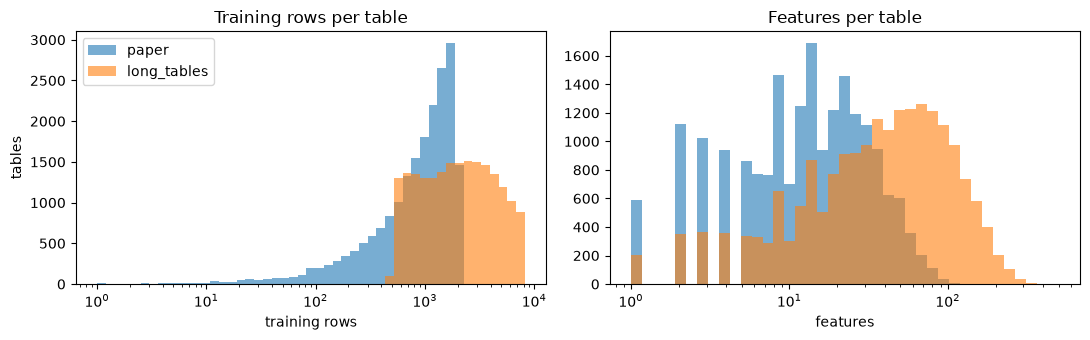

5%   중앙값   95%
paper       학습 행 수     104  1008  1935
            feature 수    2    13    49
long_tables 학습 행 수     590  1978  6656
            feature 수    4    40   152

In [5]:
def sample_sizes(config, n=20_000, seed=0):
    rng = np.random.default_rng(seed)
    sizes = [
        sample_table_size(
            rng,
            config.max_train_rows,
            config.n_eval_rows,
            config.max_features,
            min_train_rows=config.min_train_rows,
            log_uniform_rows=config.log_uniform_rows,
            max_cells=config.max_cells,
            feature_scale=config.feature_scale,
        )
        for _ in range(n)
    ]
    return np.array(sizes)  # (n, 2): 학습 행 수, feature 수


sizes = {"paper": sample_sizes(first), "long_tables": sample_sizes(second)}

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
for name, s in sizes.items():
    axes[0].hist(s[:, 0], bins=np.geomspace(1, 8192, 50), alpha=0.6, label=name)
    axes[1].hist(s[:, 1], bins=np.geomspace(1, 500, 40), alpha=0.6, label=name)
axes[0].set(xscale="log", xlabel="training rows", ylabel="tables", title="Training rows per table")
axes[1].set(xscale="log", xlabel="features", title="Features per table")
axes[0].legend()
plt.tight_layout()
plt.show()

summary = {}
for name, s in sizes.items():
    for col, label in [(0, "학습 행 수"), (1, "feature 수")]:
        summary[(name, label)] = np.percentile(s[:, col], [5, 50, 95])
display(pd.DataFrame(summary, index=["5%", "중앙값", "95%"]).T.round(0).astype(int))

2단계에서 학습 행 수의 중앙값은 1,008개에서 1,978개로, feature 수의 중앙값은 13개에서 40개로 늘어납니다. long_tables의 학습 행 수가 log 균등인데도 4,000개 위에서 줄어드는 것은, 4절의 셀 상한이 feature가 많은 표의 학습 행 수를 줄이기 때문입니다. feature 수 분포는 v2와 같은 Beta(0.95, 8)을 [1, `feature_scale`]로 편 것이라, `feature_scale`을 160에서 500으로 올리면 모양은 같고 폭만 넓어집니다.

## 4. 셀 상한: feature가 많으면 행이 줄어든다

표 하나의 셀 수(정답을 가린 행 128개까지 포함)에 상한이 있습니다. 표 크기 규칙은 feature 수를 먼저 뽑고, 셀 상한에 맞춰 학습 행 수의 상한을 줄입니다: 학습 행 ≤ (셀 상한 − 1) ÷ feature 수 − 128. feature 수별로 손으로 계산하면 다음과 같습니다.

In [6]:
def max_train_rows(config, n_features):
    # 셀 상한에 맞춘 학습 행 수 상한 (sample_table_size와 같은 계산)
    if n_features > config.max_features:
        return "—"  # 이 설정에서는 나오지 않는 feature 수
    by_cells = (config.max_cells - 1) // n_features - config.n_eval_rows
    return min(config.max_train_rows, by_cells)


cap_rows = {}
for n_features in [10, 40, 100, 152, 500]:
    cap_rows[n_features] = {
        "paper (셀 75,000, 행 ≤ 2,048)": max_train_rows(first, n_features),
        "long_tables (셀 400,000, 행 ≤ 8,192)": max_train_rows(second, n_features),
    }
display(pd.DataFrame(cap_rows).T.rename_axis("feature 수"))

,"paper (셀 75,000, 행 ≤ 2,048)","long_tables (셀 400,000, 행 ≤ 8,192)"
feature 수,,
10,2048,8192
40,1746,8192
100,621,3871
152,365,2503
500,—,671


2단계에서 학습 행을 8,192개까지 다 쓰는 것은 feature가 48개 이하인 표뿐입니다. feature 100개면 3,871개, 3절의 95% 분위인 152개면 2,503개까지 줄고, 500개면 671개입니다. 1단계에서는 feature가 35개만 되어도 2,048개보다 줄어듭니다. 그래서 2단계도 "행 8,192개 × feature 500개" 같은 표는 만들지 않습니다. 긴 표는 좁게, 넓은 표는 짧게 나옵니다.

## 5. 처음부터가 아니라 이어서 학습하는 이유

긴 표는 계산이 많이 듭니다. sample attention은 열마다 행 $R$개가 서로를 보므로 $R^2$에 비례하고, 열(토큰) 수 $C$만큼 반복됩니다. 3절에서 뽑은 표로 셀 수와 sample attention 계산량 $C \cdot R^2$의 평균을 비교합니다. $R$에는 정답을 가린 행 128개와 thinking 행 64개를 더하고, $C$는 셀 3개 묶음 수에 y 토큰 하나를 더한 것입니다.

In [7]:
cost = {}
for name, s in sizes.items():
    n_train, n_features = s[:, 0], s[:, 1]
    rows = n_train + 128 + 64  # 학습 + 정답을 가린 행 + thinking 행
    tokens = -(-n_features // 3) + 1  # 셀 3개 묶음 + y 토큰
    cost[name] = {
        "셀 수 평균": ((n_train + 128) * n_features).mean(),
        "sample attention C·R² 평균": (tokens * rows.astype(float) ** 2).mean(),
    }
cost_table = pd.DataFrame(cost).T
cost_table.loc["비율 (long_tables / paper)"] = (
    cost_table.loc["long_tables"] / cost_table.loc["paper"]
)
display(cost_table.style.format("{:,.1f}"))

,셀 수 평균,sample attention C·R² 평균
paper,"19,817.1","12,450,488.0"
long_tables,"130,536.4","172,060,890.4"
비율 (long_tables / paper),6.6,13.8


2단계 표는 셀이 평균 6.6배, sample attention 계산이 14배 많습니다. 2단계 크기로 처음부터 오래 학습하면 같은 GPU 시간에 훨씬 적은 표밖에 보지 못합니다. 그래서 대부분의 학습은 싼 1단계에서 하고, 2단계는 짧게 붙입니다.

2단계를 시작하는 방식도 정했습니다. 1단계 run의 checkpoint에서 가중치만 가져오고(`--init-run-id`), optimizer 상태와 학습률 스케줄은 새로 시작합니다(warmup 1,000 step, 그다음 cosine으로 20,000 step까지). 모델 구조는 그대로라 1단계와 같은 클래스·같은 state_dict입니다.

## 6. 어떻게 돌리나

학습과 평가는 v2와 같은 스크립트(`scripts/tabpfn_v2/{train,eval}.py`)이고, 2.5 설정을 고르는 AI Runtime yaml은 `scripts/tabpfn_v2_5/{train,eval}.yaml`에 있습니다. 명령은 저장소 루트에서 돌립니다. `$MLFLOW_EXPERIMENT_DIR`는 `.env.local`에 둔 experiment 폴더입니다.

1단계 전에 먼저 medium 설정으로 짧게 돌려 step 시간과 GPU 메모리를 잽니다(yaml 기본값: 8×H100, 2.5 분류, 300 step).

```bash
databricks air run -f scripts/tabpfn_v2_5/train.yaml --watch --override mlflow_experiment_directory=$MLFLOW_EXPERIMENT_DIR
```

yaml의 기본값은 실측용입니다(`TABPFN_V2_STEPS=300`, `timeout_minutes: 60`, run 이름 `tabpfn-v2-5-timing-300steps-8gpu`). 그래서 실제 학습에서는 step 수, 제한 시간, run 이름을 꼭 덮어씁니다. step 수를 덮어쓰지 않으면 설정 이름을 바꿔도 300 step만 돕니다.

1단계(paper)는 100k step씩 끊어 이어 학습합니다. 제한 시간은 실측한 step 시간으로 정합니다. 회귀는 `TABPFN_V2_TASK=regression`을 더합니다.

```bash
databricks air run -f scripts/tabpfn_v2_5/train.yaml --watch --override mlflow_experiment_directory=$MLFLOW_EXPERIMENT_DIR \
  --override env_variables.TABPFN_V2_CONFIG_NAME=paper --override env_variables.TABPFN_V2_STEPS=<전체 step> \
  --override env_variables.TABPFN_V2_STOP_STEP=<이번 chunk 끝> \
  --override mlflow_run_name=tabpfn-v2-5-<task>-paper-chunkNN --override timeout_minutes=<추정 시간>
# 이어서: --override env_variables.TABPFN_V2_RESUME_RUN_ID=<run_id>
```

2단계(long_tables)는 1단계 run의 가중치에서 시작합니다. step 수는 `long_tables`의 20,000을 그대로 넘깁니다.

```bash
databricks air run -f scripts/tabpfn_v2_5/train.yaml --watch --override mlflow_experiment_directory=$MLFLOW_EXPERIMENT_DIR \
  --override env_variables.TABPFN_V2_CONFIG_NAME=long_tables --override env_variables.TABPFN_V2_STEPS=20000 \
  --override env_variables.TABPFN_V2_INIT_RUN_ID=<paper run_id> --override env_variables.TABPFN_V2_INIT_STEP=<step> \
  --override mlflow_run_name=tabpfn-v2-5-<task>-long-tables --override timeout_minutes=<추정 시간>
```

평가는 v2와 같은 benchmark(v2 논문 Supplementary Tables 1·2의 분류 29개, 회귀 28개)에서 100k step 단위 checkpoint로 합니다. 멤버 전처리는 yaml 기본값이 v2.5 묶음입니다([04 노트북](04_inference_preprocessing.ipynb) 1.4).

```bash
databricks air run -f scripts/tabpfn_v2_5/eval.yaml --watch --override mlflow_experiment_directory=$MLFLOW_EXPERIMENT_DIR \
  --override "env_variables.TABPFN_V2_EXTRA_ARGS=--suite classification --classifier-path runs:/<run_id>/checkpoints/step_0100000.pt"
```

로컬에서는 같은 학습 스크립트를 smoke 크기로 돌려 2.5 구조의 코드 경로를 확인할 수 있습니다. 층 수와 임베딩 크기는 smoke 설정(2층, emsize 32) 그대로 두고, 셀 3개 묶기와 회귀 MLP encoder는 2.5대로 쓰며, thinking 행은 4개로 줄입니다. 2.5 회귀 구조로 20 step 돌립니다(CPU에서 30초 안팎).

In [8]:
repo = Path.cwd().parents[1]
pythonpath = os.pathsep.join(p for p in [str(repo / "src"), os.environ.get("PYTHONPATH")] if p)
env = {
    **os.environ,
    "PYTHONHASHSEED": "1",
    "MLFLOW_DISABLE_AGENT_HINT": "1",
    "PYTHONPATH": pythonpath,
}
env.pop("MLFLOW_TRACKING_URI", None)  # 로컬 임시 폴더에 기록한다

with tempfile.TemporaryDirectory() as tmp:
    command = [
        sys.executable,
        str(repo / "scripts" / "tabpfn_v2" / "train.py"),
        "--config-name",
        "smoke",
        "--arch",
        "v2.5",
        "--task",
        "regression",
        "--out-dir",
        tmp,
    ]
    result = subprocess.run(command, cwd=tmp, env=env, capture_output=True, text=True)
    if result.returncode != 0:  # 실패하면 스크립트의 오류 메시지를 보여 준다
        print(result.stderr[-3000:])
        raise RuntimeError(f"smoke 학습 실패 (exit {result.returncode})")
    for line in result.stdout.splitlines():
        if line.startswith(("step", "  val", "regression borders")):
            print(line)
    saved = json.loads((Path(tmp) / "train_config.json").read_text())

keys = ["task", "nlayers", "features_per_group", "n_thinking_rows", "encoder", "emsize"]
display(pd.Series({k: saved[k] for k in keys}, name="smoke 설정").to_frame())

regression borders: 40 datasets, 7s
step 5/20 loss 2.0136 lr 9.33e-04 0.222s/step wait 91% skipped 0
step 10/20 loss 6.8609 lr 5.87e-04 0.315s/step wait 96% skipped 0
  val val_loss 15.4912
step 15/20 loss 1.6276 lr 1.79e-04 0.171s/step wait 84% skipped 0
step 20/20 loss 2.6816 lr 0.00e+00 0.304s/step wait 95% skipped 0
  val val_loss 15.4786


,smoke 설정
task,regression
nlayers,2
features_per_group,3
n_thinking_rows,4
encoder,mlp
emsize,32


다음 노트북 [04 추론 전처리](04_inference_preprocessing.ipynb)는 모델 밖에서 바뀐 둘째, 추론 때 앙상블 멤버의 전처리(robust scaling + soft clipping)를 보고, 2.5 재현에서 논문에 없어서 여기서 정한 것을 모두 모읍니다.